# Analytical verification of the 2.5D electrical resistivity backend

**GPGN 436 · Molly Bilhartz · Survey upgrade, Step 4**

This notebook imports the production source-pair solver and receiver module independently of Panel. It verifies their mathematical building blocks and compares a **nonzero** layered-earth response with an independent image-source solution. It also records mesh, Fourier-integration, and finite-domain sensitivity separately.

The existing `verification.ipynb` continues to verify the original fixed-voltage 2D application. The new electrode backend is **not yet connected to the Panel interface**. This notebook verifies that backend in preparation for the later survey/interface stages; it does not claim that the current Panel app already uses it.

Run **Restart Kernel and Run All Cells** from the repository root, using the environment containing `requirements-notebook.txt`. No external data are needed. The larger domain/grid cases may take several minutes. Figures are embedded below; reproducible CSV/JSON and PNG/PDF copies are written under ignored `outputs/verification_2p5d/`.

AI assistance is disclosed in [AI_USE.md](AI_USE.md). The course PDF's numerical-verification rubric motivates this document's analytical comparison, errors, refinement, and saved outputs. Its instructions are assignment criteria, not additional requests to change the application or publish it.

## 1. Physical model and boundary conditions

Conductivity $\sigma(x,z)>0$ is isotropic and independent of cross-line $y$. Point electrodes lie at $y=z=0$: A injects $+I$ amperes and B withdraws $I$. Depth $z$ is positive down. In the conducting interior,

$$\nabla\cdot(\sigma\nabla V)=0,\qquad \mathbf J=-\sigma\nabla V.$$

Surface injection is the boundary flux $J_z(x,y,0)=I[\delta(x-x_A)-\delta(x-x_B)]\delta(y)$. The remainder of the flat surface is insulating. This is a steady elliptic problem: **no initial condition, time step, or time-refinement analysis applies**.

Using $\widehat V=\int V e^{-iky}\,dy$, each Fourier mode has operator

$$A_\sigma(k)=-\partial_x\sigma\partial_x-\partial_z\sigma\partial_z+k^2\sigma,\qquad
V(x,0,z)=\frac1\pi\int_0^\infty\widehat V(x,k,z)\,dk.$$

The code separates an analytical homogeneous primary from a numerical secondary correction. The **secondary** has zero top normal derivative and zero value at side/bottom faces. Thus the **total** potential at outer walls equals the homogeneous primary. These walls approximate an infinite half-space; the layered-earth reference below does not exactly satisfy those artificial wall values. We measure this discrepancy rather than treating the walls as exact open boundaries. The entire top conductivity row must be background material.

Cell-centered finite differences use shared harmonic face conductivity, $\sigma_f=2\sigma_P\sigma_N/(\sigma_P+\sigma_N)$, and $T_f=\sigma_f\,\text{face length}/\text{center distance}$. The operator includes $k^2\sigma\,dx\,dz$ on its diagonal. Point-source current spreads in 3D despite the 2D conductivity mesh.

In [1]:
%matplotlib inline
from pathlib import Path
from dataclasses import replace
import csv, hashlib, html, json, platform, sys
from importlib.metadata import version

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import NullLocator
from IPython.display import HTML, display
from scipy.sparse import diags
from scipy.sparse.linalg import spsolve
from scipy.special import k0

from tunnel_resistivity.electrodes import wenner, schlumberger, dipole_dipole
from tunnel_resistivity.geometry import circular_tunnel
from tunnel_resistivity.solver_2p5d import solve_source_pair, log_wavenumber_quadrature, _assemble_operator
from tunnel_resistivity.receivers import measure_receivers, sample_surface_potential

ROOT=Path.cwd()
assert (ROOT/'tunnel_resistivity/solver_2p5d.py').exists(), 'Run with the repository root as the working directory'
OUT=ROOT/'outputs/verification_2p5d'
OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':110,'font.size':10})
checks=[]

def check(name,passed,detail):
    checks.append({'check':name,'passed':bool(passed),'detail':str(detail)})
    assert passed, f'{name}: {detail}'

def table(rows):
    headers=list(rows[0])
    def cell(value):
        return html.escape(f'{value:.8g}' if isinstance(value,(float,np.floating)) else str(value))
    markup='<table><thead><tr>'+''.join(f'<th>{html.escape(h)}</th>' for h in headers)+'</tr></thead><tbody>'
    markup+=''.join('<tr>'+''.join(f'<td>{cell(row[h])}</td>' for h in headers)+'</tr>' for row in rows)
    display(HTML(markup+'</tbody></table>'))

def save_csv(name,rows):
    with (OUT/f'{name}.csv').open('w',newline='') as handle:
        writer=csv.DictWriter(handle,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)

def save_figure(fig,name):
    fig.savefig(OUT/f'{name}.png',dpi=160)
    fig.savefig(OUT/f'{name}.pdf')
    display(fig);plt.close(fig)

versions={'python':platform.python_version(),**{name:version(name) for name in ('numpy','scipy','matplotlib','nbclient','ipykernel')}}
source_hashes={str(p):hashlib.sha256(p.read_bytes()).hexdigest()
               for p in map(Path,('tunnel_resistivity/solver.py','tunnel_resistivity/solver_2p5d.py',
                                  'tunnel_resistivity/electrodes.py','tunnel_resistivity/receivers.py',
                                  'tunnel_resistivity/geometry.py'))}
print('Interpreter:',sys.executable)
print(json.dumps(versions,indent=2))
print('Output directory:',OUT)

Interpreter: /workspace/Geophysical_Computing_final_project_software_design_mhb/.venv/bin/python
{
  "python": "3.12.14",
  "numpy": "2.3.5",
  "scipy": "1.17.0",
  "matplotlib": "3.10.8",
  "nbclient": "0.11.0",
  "ipykernel": "7.4.0"
}
Output directory: /workspace/Geophysical_Computing_final_project_software_design_mhb/outputs/verification_2p5d


## 2. Homogeneous half-space: fields, polarity, and apparent resistivity

For $\rho_0=1/\sigma_0$ and $r_Q=\sqrt{(x-x_Q)^2+z^2}$,

$$V_p=\frac{\rho_0 I}{2\pi}\left(\frac1{r_A}-\frac1{r_B}\right).$$

Each $1/r$ is harmonic in 3D away from its source, so the PDE holds for constant conductivity. Its vertical derivative is zero at $z=0$ away from electrodes, and the coefficient follows hemispherical current balance $2\pi r^2 J_r=I$. The balanced pair tends to zero at infinity, fixing the potential datum.

For receivers, $\Delta V=V_M-V_N$, $K=2\pi/(1/AM-1/BM-1/AN+1/BN)$ and $\rho_a=K\Delta V/I$. Independent closed forms are $2\pi a$ (Wenner), $\pi(L^2-l^2)/(2l)$ (Schlumberger), and **$-\pi an(n+1)(n+2)$** for our A–B–M–N dipole–dipole order. Negative homogeneous voltage and negative K must give positive $\rho_a$.

This test checks units, source amplitude, analytical primary evaluation, receiver sampling and polarity. **The numerical secondary is zero by construction in homogeneous earth. A machine-precision pass does not establish convergence of the nonzero numerical solver.**

array,voltage_V,K_m,rho_a_ohm_m,max_V_error_V,relative_V_RMSE,max_J_error_A_m2,relative_rho_a_error
wenner,0.31830989,62.831853,100,4.4408921e-16,1.4074852e-16,8.6736174e-19,1.110223e-16
schlumberger,0.064305028,311.01767,100,4.4408921e-16,1.4348466e-16,3.469447e-18,1.110223e-15
dipole-dipole,-0.053051648,-376.99112,100,4.4408921e-16,1.5503391e-16,3.469447e-18,2.220446e-16


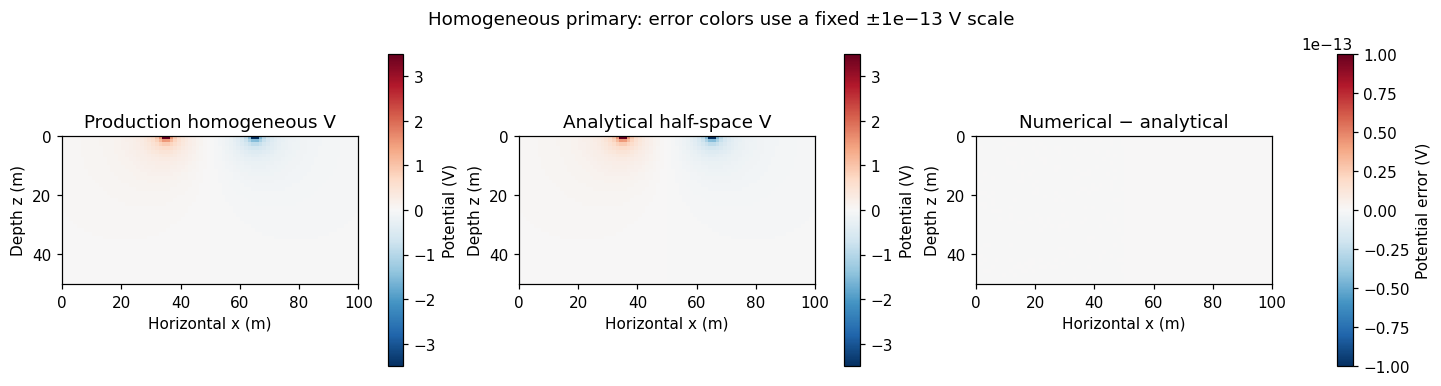

In [2]:
I=.2;rho0=100.;W,H=100.,50.
arrays=(wenner(center_x_m=50,spacing_m=10,current_a=I),
        schlumberger(center_x_m=50,ab_half_spacing_m=20,mn_half_spacing_m=2,current_a=I),
        dipole_dipole(center_x_m=50,spacing_m=5,separation_n=2,current_a=I))
closed_K=(2*np.pi*10,np.pi*(20**2-2**2)/(2*2),-np.pi*5*2*3*4)
homogeneous=[]
for array,expected_K in zip(arrays,closed_K):
    solution=solve_source_pair(np.full((40,80),1/rho0),array,width=W,height=H,n_wavenumbers=16)
    xx,zz=np.meshgrid(solution.x,solution.z)
    da,db=xx-array.a_x_m,xx-array.b_x_m
    ra,rb=np.hypot(da,zz),np.hypot(db,zz)
    exact=rho0*I/(2*np.pi)*(1/ra-1/rb)
    exact_jx=I/(2*np.pi)*(da/ra**3-db/rb**3)
    exact_jz=I/(2*np.pi)*(zz/ra**3-zz/rb**3)
    error=solution.potential-exact
    datum=measure_receivers(solution)
    row={'array':array.array_type,'voltage_V':datum.voltage_v,'K_m':datum.geometric_factor_m,
         'rho_a_ohm_m':datum.apparent_resistivity_ohm_m,'max_V_error_V':float(abs(error).max()),
         'relative_V_RMSE':float(np.linalg.norm(error)/np.linalg.norm(exact)),
         'max_J_error_A_m2':float(max(abs(solution.jx-exact_jx).max(),abs(solution.jz-exact_jz).max())),
         'relative_rho_a_error':abs(datum.apparent_resistivity_ohm_m/rho0-1)}
    homogeneous.append(row)
    check(f'Homogeneous {array.array_type}',row['relative_V_RMSE']<1e-12 and row['relative_rho_a_error']<1e-12
          and row['max_J_error_A_m2']<1e-12 and abs(datum.geometric_factor_m/expected_K-1)<1e-12,row)
    if array.array_type=='wenner':hom_solution,hom_exact=solution,exact
check('Dipole polarity',homogeneous[2]['voltage_V']<0 and homogeneous[2]['K_m']<0,'Signed K and voltage both negative')
table(homogeneous);save_csv('homogeneous',homogeneous)
fig,axes=plt.subplots(1,3,figsize=(13,3.4),layout='constrained')
limit=float(abs(hom_exact).max())
for ax,field,title in zip(axes,(hom_solution.potential,hom_exact,hom_solution.potential-hom_exact),
                         ('Production homogeneous V','Analytical half-space V','Numerical − analytical')):
    error_panel=ax is axes[2]
    image=ax.imshow(field,extent=(0,W,H,0),origin='upper',aspect='equal',cmap='RdBu_r',
                    vmin=-1e-13 if error_panel else -limit,vmax=1e-13 if error_panel else limit)
    ax.set(title=title,xlabel='Horizontal x (m)',ylabel='Depth z (m)')
    fig.colorbar(image,ax=ax,label='Potential error (V)' if error_panel else 'Potential (V)')
fig.suptitle('Homogeneous primary: error colors use a fixed ±1e−13 V scale')
save_figure(fig,'01_homogeneous')

## 3. Fourier normalization and its numerical integration

The transformed primary is

$$\widehat V_p=\frac{I}{\pi\sigma_0}[K_0(kr_A)-K_0(kr_B)],\qquad
\int_0^\infty K_0(kr)\,dk=\frac\pi{2r}.$$

Combining the identity with the inverse factor $1/\pi$ recovers the physical $1/(2\pi\sigma_0 r)$ coefficient. This independent identity checks the normalization and log-quadrature weights, including $dk=k\,d\log k$. Finite cutoffs cause truncation error even with many nodes. No $k=0$ node is used because $K_0(0)$ is singular.

In [3]:
radii=np.array([.5,1.,5.,20.])
fourier=[]
for count in (16,32,48,64,96):
    ks,weights=log_wavenumber_quadrature(n_wavenumbers=count,k_min=1e-10,k_max=80.)
    integrals=np.sum(weights[:,None]*k0(ks[:,None]*radii),axis=0)
    relative=abs(integrals/(np.pi/(2*radii))-1)
    fourier.append({'nodes':count,'k_min_per_m':1e-10,'k_max_per_m':80.,'max_relative_integral_error':float(relative.max())})
check('Bessel inverse normalization',fourier[-1]['max_relative_integral_error']<1e-7,fourier[-1])
table(fourier);save_csv('fourier_identity',fourier)

nodes,k_min_per_m,k_max_per_m,max_relative_integral_error
16,1e-10,80,0.04758517
32,1e-10,80,0.00043282873
48,1e-10,80,1.0689635e-06
64,1e-10,80,2.9264875e-08
96,1e-10,80,2.6923401e-08


## 4. Spatial convergence of the production Fourier operator

A manufactured test exercises the **same** `_assemble_operator` used inside `solve_source_pair`, without point-source singularities, interface stair steps, or inverse Fourier quadrature. We do not copy a finite-difference assembly or introduce another production solver. We prescribe a known mode and derive its forcing for a verification-only linear solve using the production matrix.

Let $W=20$ m, $H=10$ m, $k=0.2$ m$^{-1}$,

$$u(x,z)=U\sin(\alpha x)\cos(\gamma z),\quad U=1\ \mathrm{V\,m},\quad
\alpha=\pi/W,\quad\gamma=\pi/(2H),\quad
\sigma(x)=\sigma_0(1+\beta x/W).$$

Both $\beta=0$ and $\beta=1.5$ keep conductivity positive. Substitution gives

$$f=A_\sigma(k)u=
\sigma(\alpha^2+\gamma^2+k^2)u
-\frac{\sigma_0\beta}{W}U\alpha\cos(\alpha x)\cos(\gamma z).$$

The same secondary boundaries match exactly: $u=0$ at $x=0,W$ and $z=H$; $\partial_z u=0$ at $z=0$. Cell-integrated forcing is $f\,dx\,dz$ in amperes. This is a **forced mode verification problem**, not a claim that the physical source-pair problem has volume sources.

We report RMSE and maximum error at cell centers, with observed $p=\log(E_h/E_{h/2})/\log 2$. No rate is assumed. A separate reconstruction of face fluxes checks local balance including the **$k^2$ term**. In 2.5D, testing only 2D divergence would omit cross-line current spreading.

beta,nx,nz,h_m,RMSE_V_m,max_error_V_m,observed_p,relative_residual,relative_local_balance
0,16,8,1.25,0.00088765782,0.0017582595,None,9.8802616e-15,8.6256252e-15
0,32,16,0.625,0.00022183316,0.00044259813,2.0005286,4.9511867e-14,5.1380239e-14
0,64,32,0.3125,5.5453204e-05,0.00011083961,2.0001323,2.118326e-13,2.0095345e-13
0,128,64,0.15625,1.3862983e-05,2.7721791e-05,2.0000331,1.3269675e-12,1.4242142e-12
1.5,16,8,1.25,0.0013196875,0.0036359363,None,8.4479108e-15,9.9685348e-15
1.5,32,16,0.625,0.00033250117,0.0010278947,1.988765,7.5961526e-14,7.0571795e-14
1.5,64,32,0.3125,8.3289979e-05,0.00027220614,1.9971446,1.9172202e-13,2.3158001e-13
1.5,128,64,0.15625,2.0832843e-05,6.9973511e-05,1.9992832,1.2298974e-12,1.4071103e-12


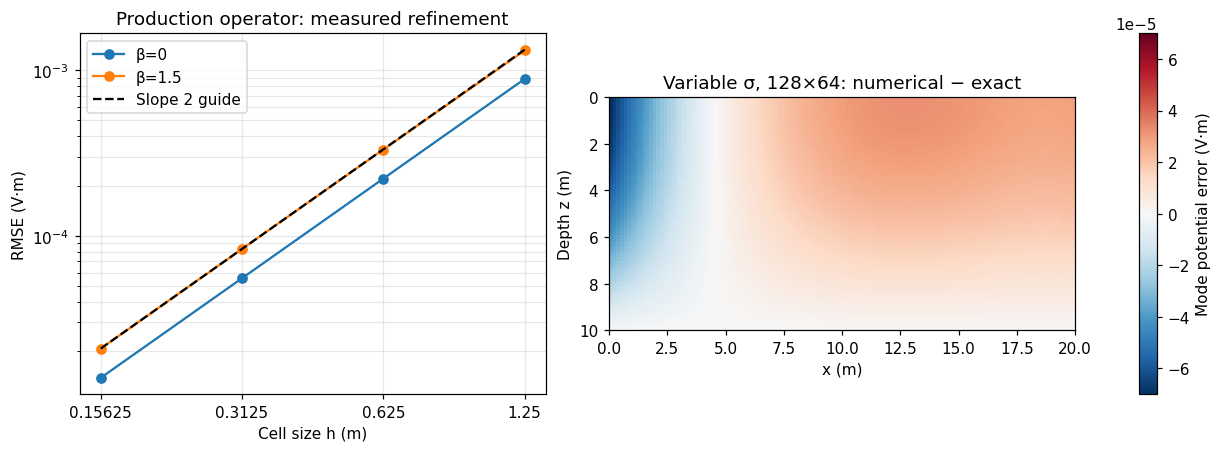

In [4]:
mode_rows=[]
for beta in (0.,1.5):
    previous_error=None
    for nx in (16,32,64,128):
        nz=nx//2;Wm,Hm,k=20.,10.,.2;dx=Wm/nx;dz=Hm/nz
        x=(np.arange(nx)+.5)*dx;z=(np.arange(nz)+.5)*dz
        xx,zz=np.meshgrid(x,z)
        sigma=.01*(1+beta*xx/Wm);alpha=np.pi/Wm;gamma=np.pi/(2*Hm)
        exact=np.sin(alpha*xx)*np.cos(gamma*zz)
        forcing=sigma*(alpha**2+gamma**2+k**2)*exact-(.01*beta/Wm)*alpha*np.cos(alpha*xx)*np.cos(gamma*zz)
        base,mass,_=_assemble_operator(sigma,dx,dz)
        matrix=base+diags(k*k*mass);rhs=forcing.ravel()*dx*dz
        values=spsolve(matrix.tocsc(),rhs).reshape(sigma.shape)
        error=values-exact;rmse=float(np.sqrt(np.mean(error**2)))
        residual=float(np.max(abs(matrix@values.ravel()-rhs))/np.max(abs(rhs)))
        # Independently reconstruct each shared face's mode current (A/m).
        jx=np.zeros((nz,nx+1));jz=np.zeros((nz+1,nx))
        sx=2/(1/sigma[:,:-1]+1/sigma[:,1:]);sz=2/(1/sigma[:-1,:]+1/sigma[1:,:])
        jx[:,1:-1]=-sx*np.diff(values,axis=1)/dx
        jx[:,0]=-2*sigma[:,0]*values[:,0]/dx
        jx[:,-1]=2*sigma[:,-1]*values[:,-1]/dx
        jz[1:-1,:]=-sz*np.diff(values,axis=0)/dz
        jz[-1,:]=2*sigma[-1,:]*values[-1,:]/dz  # top remains zero.
        flux_balance=np.diff(jx,axis=1)*dz+np.diff(jz,axis=0)*dx+k*k*sigma*dx*dz*values-rhs.reshape(sigma.shape)
        relative_balance=float(np.max(abs(flux_balance))/np.max(abs(rhs)))
        row={'beta':beta,'nx':nx,'nz':nz,'h_m':dx,'RMSE_V_m':rmse,
             'max_error_V_m':float(abs(error).max()),'observed_p':None if previous_error is None else float(np.log2(previous_error/rmse)),
             'relative_residual':residual,'relative_local_balance':relative_balance}
        mode_rows.append(row);previous_error=rmse
        check(f'Mode balance beta={beta}, nx={nx}',max(residual,relative_balance)<1e-9,row)
        if beta==1.5 and nx==128:mode_error,mode_extent=error,(0,Wm,Hm,0)
orders=[row['observed_p'] for row in mode_rows if row['observed_p'] is not None]
check('Measured smooth spatial convergence',all(1.8<p<2.2 for p in orders),orders)
table(mode_rows);save_csv('manufactured_modes',mode_rows)
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for beta in (0.,1.5):
    selected=[r for r in mode_rows if r['beta']==beta]
    hs=np.array([r['h_m'] for r in selected]);errors=np.array([r['RMSE_V_m'] for r in selected])
    axes[0].loglog(hs,errors,'o-',label=f'β={beta:g}')
axes[0].loglog(hs,errors[-1]*(hs/hs[-1])**2,'k--',label='Slope 2 guide')
axes[0].set(xlabel='Cell size h (m)',ylabel='RMSE (V·m)',title='Production operator: measured refinement')
axes[0].set_xticks(hs,[f'{h:g}' for h in hs])
axes[0].xaxis.set_minor_locator(NullLocator())
axes[0].grid(True,which='both',alpha=.3);axes[0].legend()
limit=float(abs(mode_error).max())
im=axes[1].imshow(mode_error,extent=mode_extent,origin='upper',aspect='equal',cmap='RdBu_r',vmin=-limit,vmax=limit)
axes[1].set(xlabel='x (m)',ylabel='Depth z (m)',title='Variable σ, 128×64: numerical − exact')
fig.colorbar(im,ax=axes[1],label='Mode potential error (V·m)')
save_figure(fig,'02_spatial_convergence')

## 5. An independent nonzero physical reference: two-layer earth

A homogeneous-primary test cannot verify the numerical correction. We therefore use an upper layer $\rho_1=100$ Ω·m, thickness $h=10$ m, above a half-space $\rho_2=200$ Ω·m. The reflection coefficient is

$$\kappa=\frac{\rho_2-\rho_1}{\rho_2+\rho_1}=\frac13.$$

For one surface source, with horizontal separation $d=x-x_Q$, write $G(d,s)=1/\sqrt{d^2+s^2}$. In the upper layer,

$$V_1=\frac{\rho_1 I}{2\pi}\left[G(d,z)+\sum_{n=1}^{\infty}\kappa^n\{G(d,z-2nh)+G(d,z+2nh)\}\right].$$

In the lower layer,

$$V_2=\frac{\rho_1 I}{2\pi}(1+\kappa)\sum_{n=0}^{\infty}\kappa^nG(d,z+2nh).$$

Subtract B's field from A's. Every image kernel is harmonic away from its image, the paired upper images give zero top derivative, and the coefficient satisfies $\sigma_1(1-\kappa)=\sigma_2(1+\kappa)$. Consequently potential and vertical current are continuous at $z=h$. We check these interface identities explicitly using $\partial_sG=-s/(d^2+s^2)^{3/2}$.

At the surface this reduces to $\rho_1I/(2\pi)[1/|d|+2\sum_{n\ge1}\kappa^n/\sqrt{d^2+(2nh)^2}]$. The functions below are **analytical series evaluators, not PDE solvers**. They do not call the production primary or receiver formulas. We verify image-series truncation separately.

In [5]:
def layer_reference(x,z,array,*,side='upper',images=80):
    """Analytical physical V and Jz for the stated 100/200 Ω·m, h=10 m case."""
    x,z=np.broadcast_arrays(np.asarray(x,dtype=float),np.asarray(z,dtype=float))
    potential=np.zeros_like(x);derivative=np.zeros_like(x)
    h,rho1,rho2,kappa=10.,100.,200.,1/3
    for source,sign in ((array.a_x_m,1),(array.b_x_m,-1)):
        d=x-source
        if side=='upper':
            offsets=[(1.,z)]+[(kappa**n,z+sgn*2*n*h) for n in range(1,images+1) for sgn in (-1,1)]
            rho=rho1
        elif side=='lower':
            offsets=[((1+kappa)*kappa**n,z+2*n*h) for n in range(images+1)]
            rho=rho2
        else:raise ValueError('side must be upper or lower')
        for weight,s in offsets:
            r=np.hypot(d,s)
            potential+=sign*weight/r
            derivative-=sign*weight*s/r**3
    factor=rho1*array.current_a/(2*np.pi)
    return factor*potential,-factor*derivative/rho

reference_array=wenner(center_x_m=240,spacing_m=10,current_a=1)
series_rows=[]
for count in (4,8,16,32,64,80):
    values,_=layer_reference([reference_array.m_x_m,reference_array.n_x_m],0,reference_array,images=count)
    series_rows.append({'image_pairs':count,'voltage_V':float(values[0]-values[1])})
exact_voltage=series_rows[-1]['voltage_V'];exact_rhoa=2*np.pi*10*exact_voltage
check('Image-series truncation',abs(series_rows[-2]['voltage_V']-exact_voltage)<1e-12,series_rows[-2:])
interface_x=reference_array.center_x_m+np.array([-25.,-7.7,3.,24.])
upper_v,upper_j=layer_reference(interface_x,10,reference_array,side='upper')
lower_v,lower_j=layer_reference(interface_x,10,reference_array,side='lower')
interface_v_error=float(np.max(abs(upper_v-lower_v))/np.max(abs(upper_v)))
interface_j_error=float(np.max(abs(upper_j-lower_j))/np.max(abs(upper_j)))
check('Analytical layer interface continuity',max(interface_v_error,interface_j_error)<1e-12,
      {'relative_V_jump':interface_v_error,'relative_Jz_jump':interface_j_error})
table(series_rows);save_csv('layer_series',series_rows)
print(f'Exact receiver ΔV = {exact_voltage:.12f} V; exact ρa = {exact_rhoa:.12f} Ω·m')
print('Interface relative jumps: V =',interface_v_error,'Jz =',interface_j_error)

image_pairs,voltage_V
4,1.8053914
8,1.8054385
16,1.8054386
32,1.8054386
64,1.8054386
80,1.8054386


Exact receiver ΔV = 1.805438647386 V; exact ρa = 113.439055822693 Ω·m
Interface relative jumps: V = 1.942364692916669e-15 Jz = 4.278760187956347e-16


### Mesh refinement and domain extension are different experiments

Use Wenner $a=10$ m and $I=1$ A, centered in each domain. Layer depth is aligned with cell faces at all tested spacings. All layered runs below use **fixed** inverse-Fourier cutoffs $[10^{-8},8]$ m$^{-1}$ and 64 nodes, so changing a grid does not also change the integration interval. The later integration check tests that choice.

We compare cell potentials only in the upper-layer region $|x-x_c|<10$ m, $z<5$ m, away from source singularities. Cell errors are normalized by the RMS **exact secondary correction**, not by the much larger primary. Receiver error is also reported relative to the nonzero exact secondary voltage and, separately, to total $\rho_a$. These denominators mean different things.

For spatial refinement, keep the domain 480×320 m. For the boundary experiment, enlarge it to 960×640 m **at the same 2.5 m cell spacing**, translating electrodes with the center. The infinite-domain reference uses identical physical layer/source parameters but does not match the artificial primary-valued walls. These errors therefore include boundary approximation, not only finite-difference truncation.

In [6]:
SPECTRAL={'n_wavenumbers':64,'k_min':1e-8,'k_max':8.}
layer_cache={};layer_rows=[]

def layer_run(width,height,nx,nz,*,count=64,k_min=1e-8,k_max=8.):
    key=(width,height,nx,nz,count,k_min,k_max)
    if key not in layer_cache:
        z=(np.arange(nz)+.5)*height/nz
        sigma=np.broadcast_to(np.where(z[:,None]<10,.01,.005),(nz,nx)).copy()
        array=wenner(center_x_m=width/2,spacing_m=10,current_a=1)
        layer_cache[key]=solve_source_pair(sigma,array,width=width,height=height,
                                          n_wavenumbers=count,k_min=k_min,k_max=k_max)
    return layer_cache[key]

for width,height,nx,nz in ((480.,320.,96,64),(480.,320.,192,128),
                            (480.,320.,384,256),(960.,640.,384,256)):
    model=layer_run(width,height,nx,nz)
    datum=measure_receivers(model)
    xx,zz=np.meshgrid(model.x,model.z)
    keep=(abs(xx-width/2)<10)&(zz<5)
    exact_cells,_=layer_reference(xx[keep],zz[keep],model.electrodes)
    exact_secondary=exact_cells-model.primary_potential[keep]
    cell_error=model.potential[keep]-exact_cells
    secondary_voltage_exact=exact_voltage-datum.primary_voltage_v
    row={'width_m':width,'height_m':height,'nx':nx,'nz':nz,'h_m':model.dx,
         'cell_RMSE_V':float(np.sqrt(np.mean(cell_error**2))),
         'relative_secondary_cell_error':float(np.linalg.norm(cell_error)/np.linalg.norm(exact_secondary)),
         'voltage_V':datum.voltage_v,'rho_a_ohm_m':datum.apparent_resistivity_ohm_m,
         'signed_rho_a_error_ohm_m':datum.apparent_resistivity_ohm_m-exact_rhoa,
         'relative_rho_a_error':abs(datum.voltage_v-exact_voltage)/abs(exact_voltage),
         'relative_secondary_voltage_error':abs(datum.voltage_v-exact_voltage)/abs(secondary_voltage_exact),
         'mode_residual':model.max_relative_mode_residual,'mode_balance':model.max_relative_mode_balance_error,
         'seconds':model.elapsed_seconds}
    layer_rows.append(row)
    check(f'Layer algebraic diagnostics {width:g} m, h={model.dx:g}',
          max(row['mode_residual'],row['mode_balance'])<1e-9,row)
    print(f'Completed domain {width:g}×{height:g}, grid {nx}×{nz}, ρa={datum.apparent_resistivity_ohm_m:.9f}',flush=True)
benchmark=layer_rows[1]
check('Nonzero layered production benchmark',benchmark['relative_secondary_cell_error']<.01
      and benchmark['relative_secondary_voltage_error']<.01 and benchmark['relative_rho_a_error']<.001,benchmark)
table(layer_rows);save_csv('layer_mesh_domain',layer_rows)

Completed domain 480×320, grid 96×64, ρa=113.442799795


Completed domain 480×320, grid 192×128, ρa=113.436169173


Completed domain 480×320, grid 384×256, ρa=113.429155430


Completed domain 960×640, grid 384×256, ρa=113.447196891


width_m,height_m,nx,nz,h_m,cell_RMSE_V,relative_secondary_cell_error,voltage_V,rho_a_ohm_m,signed_rho_a_error_ohm_m,relative_rho_a_error,relative_secondary_voltage_error,mode_residual,mode_balance,seconds
480,320,96,64,5,0.0025423744,0.021107616,1.8054982,113.4428,0.0037439722,3.3004261e-05,0.00027858893,8.2637375e-15,1.7870541e-15,1.4921162
480,320,192,128,2.5,0.00060457408,0.0048853065,1.8053927,113.43617,-0.0028866494,2.5446698e-05,0.00021479555,1.8774542e-14,5.96414e-15,7.9396584
480,320,384,256,1.25,6.9216484e-05,0.00055560029,1.8052811,113.42916,-0.0099003924,8.7274989e-05,0.00073668809,4.7915452e-14,1.0745399e-14,50.142147
960,640,384,256,2.5,0.0007043642,0.0056916681,1.8055682,113.4472,0.0081410684,7.176601e-05,0.00060577681,1.6427724e-14,7.2124533e-15,55.797623


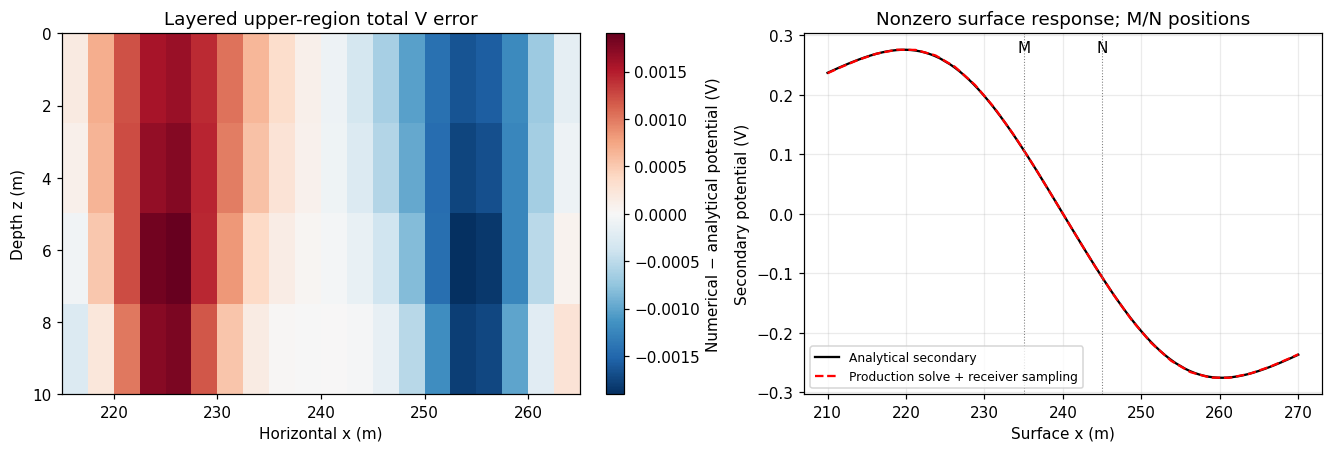

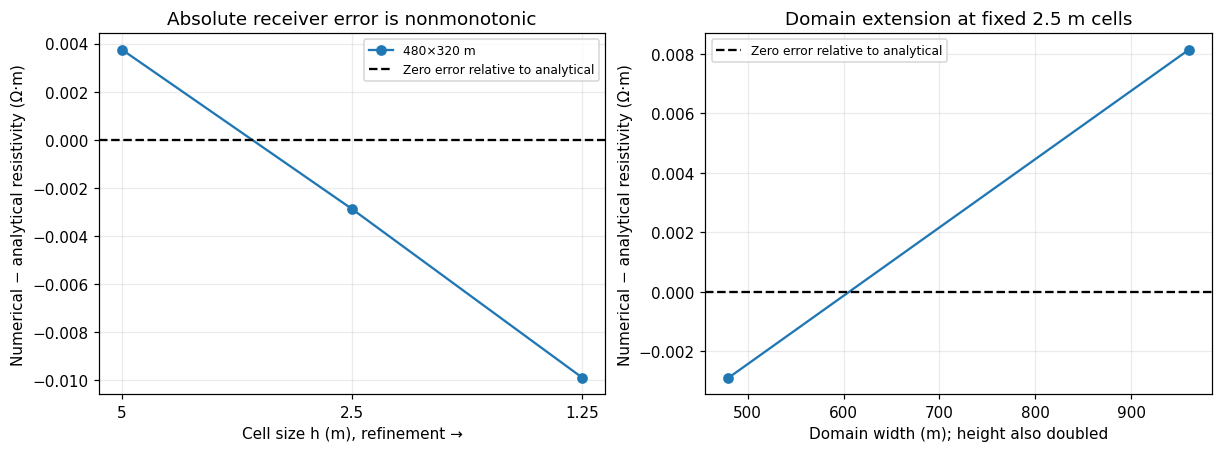

Successive mesh changes (Ω·m): [-0.00663062 -0.00701374]
Fixed-spacing domain change (Ω·m): 0.011027717810918602
These data do not establish an asymptotic end-to-end receiver convergence rate.


In [7]:
model=layer_run(480.,320.,192,128)
# Plot the upper layer only: the independent upper reference is valid there.
ix=abs(model.x-240)<25;iz=model.z<10
xx,zz=np.meshgrid(model.x[ix],model.z[iz])
exact_upper,_=layer_reference(xx,zz,model.electrodes)
error=model.potential[np.ix_(iz,ix)]-exact_upper
surface_x=np.linspace(210,270,301)
valid=(abs(surface_x-model.electrodes.a_x_m)>.5)&(abs(surface_x-model.electrodes.b_x_m)>.5)
surface_v=sample_surface_potential(model,surface_x[valid])
ref_v,_=layer_reference(surface_x[valid],0,model.electrodes)
primary_v=100/(2*np.pi)*(1/abs(surface_x[valid]-model.electrodes.a_x_m)-1/abs(surface_x[valid]-model.electrodes.b_x_m))
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
limit=float(abs(error).max())
extent=(model.x[ix][0]-model.dx/2,model.x[ix][-1]+model.dx/2,model.z[iz][-1]+model.dz/2,0)
im=axes[0].imshow(error,extent=extent,origin='upper',aspect='auto',cmap='RdBu_r',vmin=-limit,vmax=limit)
axes[0].set(xlabel='Horizontal x (m)',ylabel='Depth z (m)',title='Layered upper-region total V error')
fig.colorbar(im,ax=axes[0],label='Numerical − analytical potential (V)')
axes[1].plot(surface_x[valid],ref_v-primary_v,'k-',label='Analytical secondary')
axes[1].plot(surface_x[valid],surface_v-primary_v,'r--',label='Production solve + receiver sampling')
for label,pos in (('M',model.electrodes.m_x_m),('N',model.electrodes.n_x_m)):
    axes[1].axvline(pos,color='gray',linewidth=.7,linestyle=':')
    axes[1].text(pos,.98,label,transform=axes[1].get_xaxis_transform(),ha='center',va='top')
axes[1].set(xlabel='Surface x (m)',ylabel='Secondary potential (V)',title='Nonzero surface response; M/N positions')
axes[1].legend(fontsize=8);axes[1].grid(alpha=.25)
save_figure(fig,'03_layered_comparison')

fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
mesh=layer_rows[:3]
axes[0].semilogx([r['h_m'] for r in mesh],[r['signed_rho_a_error_ohm_m'] for r in mesh],'o-',label='480×320 m')
axes[0].axhline(0,color='k',linestyle='--',label='Zero error relative to analytical')
axes[0].set_xticks([r['h_m'] for r in mesh],[f"{r['h_m']:g}" for r in mesh])
axes[0].xaxis.set_minor_locator(NullLocator())
axes[0].invert_xaxis()
axes[0].set(xlabel='Cell size h (m), refinement →',ylabel='Numerical − analytical resistivity (Ω·m)',title='Absolute receiver error is nonmonotonic')
axes[0].legend(fontsize=8);axes[0].grid(alpha=.25)
selected=[layer_rows[1],layer_rows[3]]
axes[1].plot([r['width_m'] for r in selected],[r['signed_rho_a_error_ohm_m'] for r in selected],'o-')
axes[1].axhline(0,color='k',linestyle='--',label='Zero error relative to analytical')
axes[1].set(xlabel='Domain width (m); height also doubled',ylabel='Numerical − analytical resistivity (Ω·m)',title='Domain extension at fixed 2.5 m cells')
axes[1].legend(fontsize=8);axes[1].grid(alpha=.25)
save_figure(fig,'04_mesh_and_domain')
mesh_changes=np.diff([r['signed_rho_a_error_ohm_m'] for r in mesh])
domain_change=layer_rows[3]['rho_a_ohm_m']-layer_rows[1]['rho_a_ohm_m']
print('Successive mesh changes (Ω·m):',mesh_changes)
print('Fixed-spacing domain change (Ω·m):',domain_change)
print('These data do not establish an asymptotic end-to-end receiver convergence rate.')

### Why a finer grid need not have the smallest error in this table

The analytical reference has infinite boundaries; the numerical correction is forced to zero at finite side/bottom faces. The total error combines spatial truncation, surface reconstruction, Fourier integration and wall approximation. Their signed contributions can cancel. A finer grid can remove some cancellation and increase the measured total error even though its spatial truncation decreases.

The fixed-spacing domain experiment demonstrates that the walls matter. A tiny linear residual solves the chosen finite problem accurately; it does not remove that modeling difference. The measured second-order result in Section 4 applies to its **smooth, exactly matched-boundary Fourier problem**, not automatically to these physical receiver data or a stair-stepped tunnel. No convergence rate is forced onto the layered table.

The refinement plot shows **signed** errors: negative values mean underprediction. The nonmonotonicity discussed here refers to the **absolute error magnitude**, which decreases and then increases across these three meshes.

## 6. Isolate inverse-Fourier error from grid/domain error

First repeat the layered benchmark on **one fixed mesh/domain** with 64 and 96 nodes, then extend both cutoffs with 96 nodes. Compare the full secondary field and the secondary receiver voltage. This is a sensitivity check, not an exact integration-error bound.

Next use a buried water tunnel on a smaller fixed mesh to vary node count and each cutoff separately. This exercises the actual contrast forcing and inverse transform, unlike the primary-only Bessel identity. Numerical differences are normalized by the nonzero 96-node secondary solution. None of these integration checks certifies geometry or boundary accuracy.

In [8]:
layer_quad=[]
layer_reference_numeric=layer_run(480.,320.,192,128,count=96,k_min=1e-10,k_max=16.)
layer_reference_datum=measure_receivers(layer_reference_numeric)
for label,count,low,high in (('64 fixed interval',64,1e-8,8.),('96 fixed interval',96,1e-8,8.),
                              ('96 extended interval',96,1e-10,16.)):
    m=layer_run(480.,320.,192,128,count=count,k_min=low,k_max=high);d=measure_receivers(m)
    layer_quad.append({'case':label,'nodes':count,'k_min_per_m':low,'k_max_per_m':high,
                       'relative_secondary_field_change':float(np.linalg.norm(m.secondary_potential-layer_reference_numeric.secondary_potential)/np.linalg.norm(layer_reference_numeric.secondary_potential)),
                       'relative_secondary_voltage_change':abs(d.secondary_voltage_v-layer_reference_datum.secondary_voltage_v)/abs(layer_reference_datum.secondary_voltage_v)})
check('Layer Fourier sensitivity',max(layer_quad[0]['relative_secondary_field_change'],layer_quad[0]['relative_secondary_voltage_change'])<1e-4,layer_quad[0])
table(layer_quad);save_csv('layer_fourier_sensitivity',layer_quad)

water_sigma,tunnel_mask=circular_tunnel(width=100,height=50,nx=80,nz=40,
                                       center_x=50,depth=15,radius=5,host_resistivity=100,tunnel_resistivity=5)
water_array=wenner(center_x_m=50,spacing_m=10,current_a=1)
water_cache={}
def water_run(count=96,low=1e-8,high=8.):
    key=(count,low,high)
    if key not in water_cache:
        water_cache[key]=solve_source_pair(water_sigma,water_array,n_wavenumbers=count,k_min=low,k_max=high)
    return water_cache[key]
water_ref=water_run();water_ref_datum=measure_receivers(water_ref)
water_quad=[]
for count,low,high in ((24,1e-8,8.),(48,1e-8,8.),(72,1e-8,8.),(96,1e-8,8.),
                        (96,1e-10,8.),(96,1e-8,16.)):
    m=water_run(count,low,high);d=measure_receivers(m)
    water_quad.append({'nodes':count,'k_min_per_m':low,'k_max_per_m':high,
                       'secondary_voltage_V':d.secondary_voltage_v,
                       'relative_secondary_field_change':float(np.linalg.norm(m.secondary_potential-water_ref.secondary_potential)/np.linalg.norm(water_ref.secondary_potential)),
                       'relative_secondary_voltage_change':abs(d.secondary_voltage_v-water_ref_datum.secondary_voltage_v)/abs(water_ref_datum.secondary_voltage_v)})
check('Water Fourier node and cutoff sensitivity',all(max(r['relative_secondary_field_change'],r['relative_secondary_voltage_change'])<1e-4 for r in water_quad[2:]),water_quad[2:])
table(water_quad);save_csv('water_fourier_sensitivity',water_quad)

case,nodes,k_min_per_m,k_max_per_m,relative_secondary_field_change,relative_secondary_voltage_change
64 fixed interval,64,1e-08,8,3.106713e-07,1.6529021e-07
96 fixed interval,96,1e-08,8,3.1024933e-07,1.652883e-07
96 extended interval,96,1e-10,16,0,0


nodes,k_min_per_m,k_max_per_m,secondary_voltage_V,relative_secondary_field_change,relative_secondary_voltage_change
24,1e-08,8,-0.075528469,0.0011411382,0.0011296059
48,1e-08,8,-0.07544326,2.4060089e-07,1.6251802e-07
72,1e-08,8,-0.075443248,1.5068295e-11,1.4174454e-11
96,1e-08,8,-0.075443248,0,0
96,1e-10,8,-0.075443261,1.6038002e-07,1.6616075e-07
96,1e-08,16,-0.075443248,5.1783588e-14,2.1890054e-14


## 7. Positive finite air/water contrasts: physical sanity, not an analytical tunnel solution

Use a circular cell-center anomaly at (50,15) m, radius 5 m, 100 Ω·m host and the same Wenner sources. Water is 5 Ω·m and air is represented by **finite** 1e8 Ω·m resistivity, never zero conductivity. Both numerical fields must be finite; relative mode residuals and balances must be small. In this symmetric Wenner case air should raise apparent resistivity and water should lower it. This is a qualitative consistency check, not a universal sign rule for every array/target position.

The conservative mode diagnostics include the $k^2$ mass term. Returned physical `jx/jz` are approximate cell-center currents, not conservative face arrays. $J_y=0$ at the symmetry plane but $\partial_yJ_y$ need not vanish, so a 2D physical-current divergence test is inappropriate. A circular cross-section in this backend represents a tunnel infinitely long along y.

material,min_sigma_S_m,max_sigma_S_m,secondary_voltage_V,rho_a_ohm_m,max_abs_secondary_V,mode_residual,mode_balance
Air approximation,1e-08,0.01,0.089290218,105.61027,0.272648,6.6108966e-15,5.5489569e-15
Water approximation,0.01,0.2,-0.075443248,95.259761,0.23408743,4.3640931e-15,8.7637922e-16


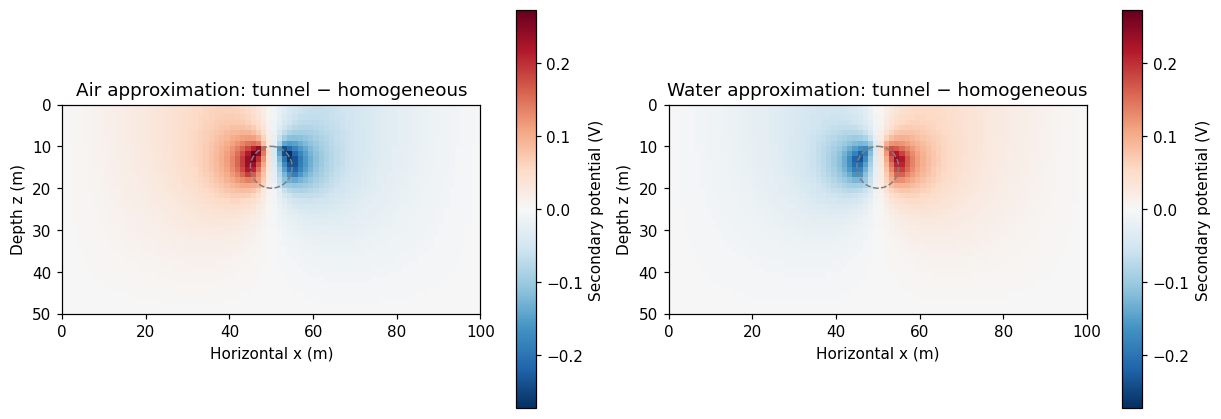

In [9]:
air_sigma,_=circular_tunnel(width=100,height=50,nx=80,nz=40,center_x=50,depth=15,radius=5,
                           host_resistivity=100,tunnel_resistivity=1e8)
air=solve_source_pair(air_sigma,water_array,n_wavenumbers=96,k_min=1e-8,k_max=8.)
tunnel_rows=[]
for name,m in (('Air approximation',air),('Water approximation',water_ref)):
    d=measure_receivers(m)
    row={'material':name,'min_sigma_S_m':float(m.conductivity.min()),
         'max_sigma_S_m':float(m.conductivity.max()),'secondary_voltage_V':d.secondary_voltage_v,
         'rho_a_ohm_m':d.apparent_resistivity_ohm_m,'max_abs_secondary_V':float(abs(m.secondary_potential).max()),
         'mode_residual':m.max_relative_mode_residual,'mode_balance':m.max_relative_mode_balance_error}
    tunnel_rows.append(row)
    check(f'{name} finite fields and modal conservation',np.all(m.conductivity>0)
          and all(np.all(np.isfinite(v)) for v in (m.potential,m.jx,m.jz,m.secondary_potential))
          and max(row['mode_residual'],row['mode_balance'])<1e-9,row)
check('Symmetric Wenner contrast signs',tunnel_rows[0]['rho_a_ohm_m']>100>tunnel_rows[1]['rho_a_ohm_m'],tunnel_rows)
table(tunnel_rows);save_csv('tunnel_sanity',tunnel_rows)
fig,axes=plt.subplots(1,2,figsize=(11,3.7),layout='constrained')
limit=max(abs(air.secondary_potential).max(),abs(water_ref.secondary_potential).max())
for ax,m,name in zip(axes,(air,water_ref),('Air approximation','Water approximation')):
    image=ax.imshow(m.secondary_potential,extent=(0,100,50,0),origin='upper',aspect='equal',
                    cmap='RdBu_r',vmin=-limit,vmax=limit)
    ax.add_patch(plt.Circle((50,15),5,fill=False,edgecolor='gray',linestyle='--'))
    ax.set(xlabel='Horizontal x (m)',ylabel='Depth z (m)',title=f'{name}: tunnel − homogeneous')
    fig.colorbar(image,ax=ax,label='Secondary potential (V)')
save_figure(fig,'05_tunnel_sanity')

## 8. Verification record, limitations, and assignment checklist

The final cell prints the measured rates and errors and saves full-precision results and source-file hashes. All acceptance assertions must succeed before the completion message appears. A pass applies to the stated cases/tolerances, not every model a user might create.

| Verification requirement | Evidence here |
| --- | --- |
| Same simulation code, independent of UI | Production `solve_source_pair`, `_assemble_operator`, and receiver imports; no Panel initialization or copied PDE assembly |
| Test problem and analytical solution | Homogeneous half-space, manufactured mode, independently evaluated two-layer image series |
| Matching physical/initial/boundary parameters | Explicit geometry/current/material values; exact manufactured boundaries; no time dependence; finite-wall mismatch measured for the infinite physical reference |
| Numerical versus analytical plots and quantitative errors | Embedded figures and tables for fields, receiver data and operator convergence |
| Error versus grid spacing | Measured manufactured orders; physical mesh table with boundary-error caveat; separate domain/integration experiments |
| Explanation of discrepancies | Homogeneous construction, Fourier truncation, receiver interpolation, interface geometry and wall effects distinguished |
| Saved executed notebook | All code cells run, with embedded image outputs; original 2D notebook retained |

**Remaining scientific limits:** primary-valued finite walls, point-electrode singularities, ideal flat surface, uniform top conductivity row, isotropic DC material properties, no contact resistance or noise, infinite tunnel extent along y, and stair-stepped circular interfaces. Small residuals and good conservation do not bound all discretization/modeling errors. Shallow interfaces may use first-row receiver reconstruction instead of the smooth quadratic. Very weak signals or extreme array separations are vulnerable to cancellation.

The smooth operator shows second-order convergence in its matched problem. The end-to-end receiver mesh study does **not** establish that rate. These are numerical verification results, not validation against field measurements or a demonstration of Onyx tunnel detectability. Survey generation and the interactive electrode UI are later stages.

References: the governing equation follows charge conservation and Ohm's law; the half-space field follows hemispherical current balance. The layer series follows interface reflection/transmission with coefficient κ and is checked for interface continuity and truncation above. Standard SciPy Bessel functions/sparse algebra and NumPy quadrature implement mathematical building blocks; no specialized geophysical package is used. See [REFERENCES.md](REFERENCES.md), [Step 2 notes](docs/SOURCE_PAIR_2P5D.md), [Step 3 notes](docs/RECEIVER_MEASUREMENTS.md), and [AI_USE.md](AI_USE.md).

In [10]:
summary={'versions':versions,'source_sha256':source_hashes,'checks':checks,
         'manufactured_orders':orders,'homogeneous':homogeneous,'fourier_identity':fourier,
         'layer_exact_voltage_V':exact_voltage,'layer_exact_apparent_resistivity_ohm_m':exact_rhoa,
         'layer_mesh_domain':layer_rows,'layer_fourier_sensitivity':layer_quad,
         'water_fourier_sensitivity':water_quad,'tunnel_sanity':tunnel_rows,
         'notes':['Homogeneous recovery is exact by construction.',
                  'Measured smooth operator convergence is not an end-to-end tunnel/receiver rate.',
                  'Infinite-reference/finite-wall mismatch and error cancellation remain.',
                  'Verification is not field validation; the current Panel app is not yet using this backend.']}
assert all(row['passed'] for row in checks)
(OUT/'summary.json').write_text(json.dumps(summary,indent=2)+'\n')
save_csv('checks',checks)
table(checks)
print(f'VERIFICATION COMPLETE: {len(checks)} acceptance checks passed.')
print('Measured spatial orders:',[round(p,6) for p in orders])
print(f'Layer benchmark apparent-resistivity error: {100*benchmark["relative_rho_a_error"]:.6g}%')
print('CSV/JSON and PNG/PDF copies:',OUT.relative_to(ROOT))

check,passed,detail
Homogeneous wenner,True,"{'array': 'wenner', 'voltage_V': 0.3183098861837907, 'K_m': 62.83185307179586, 'rho_a_ohm_m': 99.99999999999999, 'max_V_error_V': 4.440892098500626e-16, 'relative_V_RMSE': 1.4074852069984642e-16, 'max_J_error_A_m2': 8.673617379884035e-19, 'relative_rho_a_error': 1.1102230246251565e-16}"
Homogeneous schlumberger,True,"{'array': 'schlumberger', 'voltage_V': 0.06430502751187687, 'K_m': 311.0176727053894, 'rho_a_ohm_m': 99.99999999999989, 'max_V_error_V': 4.440892098500626e-16, 'relative_V_RMSE': 1.434846582991338e-16, 'max_J_error_A_m2': 3.469446951953614e-18, 'relative_rho_a_error': 1.1102230246251565e-15}"
Homogeneous dipole-dipole,True,"{'array': 'dipole-dipole', 'voltage_V': -0.053051647697298476, 'K_m': -376.99111843077503, 'rho_a_ohm_m': 100.00000000000001, 'max_V_error_V': 4.440892098500626e-16, 'relative_V_RMSE': 1.5503391248848752e-16, 'max_J_error_A_m2': 3.469446951953614e-18, 'relative_rho_a_error': 2.220446049250313e-16}"
Dipole polarity,True,Signed K and voltage both negative
Bessel inverse normalization,True,"{'nodes': 96, 'k_min_per_m': 1e-10, 'k_max_per_m': 80.0, 'max_relative_integral_error': 2.6923400509026862e-08}"
"Mode balance beta=0.0, nx=16",True,"{'beta': 0.0, 'nx': 16, 'nz': 8, 'h_m': 1.25, 'RMSE_V_m': 0.0008876578202119757, 'max_error_V_m': 0.0017582595443110804, 'observed_p': None, 'relative_residual': 9.880261641908346e-15, 'relative_local_balance': 8.625625242935857e-15}"
"Mode balance beta=0.0, nx=32",True,"{'beta': 0.0, 'nx': 32, 'nz': 16, 'h_m': 0.625, 'RMSE_V_m': 0.00022183316038658845, 'max_error_V_m': 0.00044259813347380383, 'observed_p': 2.0005286041403054, 'relative_residual': 4.9511867149586115e-14, 'relative_local_balance': 5.138023949485351e-14}"
"Mode balance beta=0.0, nx=64",True,"{'beta': 0.0, 'nx': 64, 'nz': 32, 'h_m': 0.3125, 'RMSE_V_m': 5.5453204032912547e-05, 'max_error_V_m': 0.00011083961225188954, 'observed_p': 2.0001323152120567, 'relative_residual': 2.118326007824238e-13, 'relative_local_balance': 2.0095345033871896e-13}"
"Mode balance beta=0.0, nx=128",True,"{'beta': 0.0, 'nx': 128, 'nz': 64, 'h_m': 0.15625, 'RMSE_V_m': 1.3862983087333091e-05, 'max_error_V_m': 2.7721790899382093e-05, 'observed_p': 2.0000330850608843, 'relative_residual': 1.3269674594879194e-12, 'relative_local_balance': 1.4242141967437654e-12}"
"Mode balance beta=1.5, nx=16",True,"{'beta': 1.5, 'nx': 16, 'nz': 8, 'h_m': 1.25, 'RMSE_V_m': 0.0013196875033862538, 'max_error_V_m': 0.0036359363015883855, 'observed_p': None, 'relative_residual': 8.447910811414204e-15, 'relative_local_balance': 9.96853475746876e-15}"


VERIFICATION COMPLETE: 26 acceptance checks passed.
Measured spatial orders: [2.000529, 2.000132, 2.000033, 1.988765, 1.997145, 1.999283]
Layer benchmark apparent-resistivity error: 0.00254467%
CSV/JSON and PNG/PDF copies: outputs/verification_2p5d
